In [2]:

import ast
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager
from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype'] = 'none'  

In [55]:
df=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t")

In [59]:
df=df[~df.annotation.isin(['Reject', 'Other direction'])]
df[df.sciarid_species=='Bradysia coprophila, Bradysia odoriphaga'].n_cluster_seqs.sum()

28

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import numpy as np

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


## Cyanide: time to paralysis 

In [4]:
df=pd.read_csv("outputs/drosophila_experimental_data/cyanide_data - time_to_paralysis.csv")


In [5]:
df['Genotype_og']=df['Genotype']
df['sex_og']=df['Sex']

/tmp/ipykernel_3223164/3177743851.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


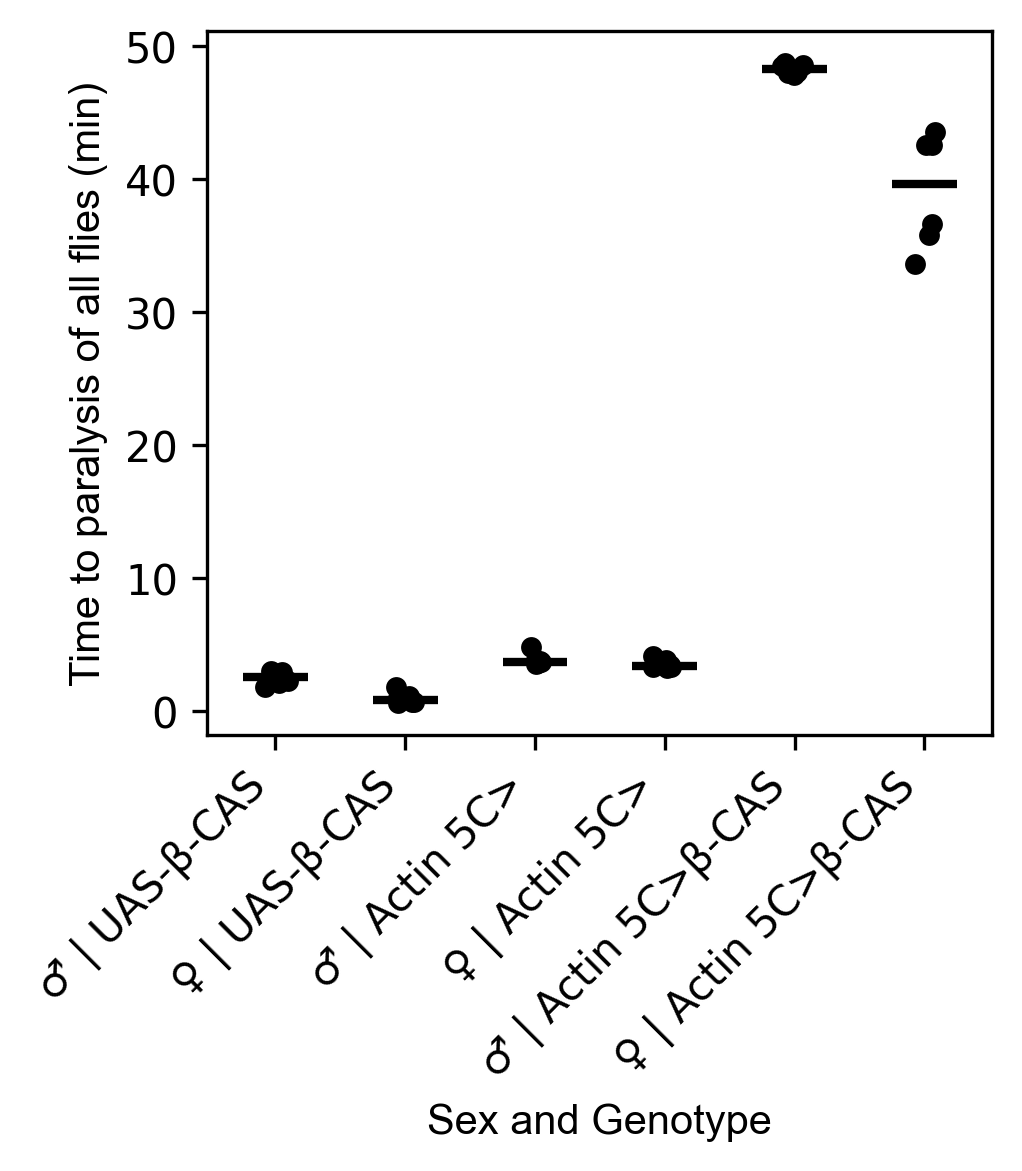

In [6]:
# Sex symbols
sex_map = {"Male": "♂", "Female": "♀", "M": "♂", "F": "♀"}
df["Sex"] = df["Sex"].map(sex_map).fillna(df["Sex"])

# --- Standardize the transgene name to β-CAS ---
# Add/adjust patterns here if your raw text varies.
df["Genotype"] = (df["Genotype"].astype(str)
                  .str.replace(r"Bcop\s*Cys\s*Synthase", "β-CAS", regex=True)
                  .str.replace(r"\bCys\s*Synthase\b", "β-CAS", regex=True))
##written by RK with chat-gpt
def pretty_genotype(g: str) -> str:
    g = g.strip()

    # Remove common trailing wildtype markers
    g = re.sub(r"\s*/\s*\+\s*$", "", g)      # "/+"
    g = re.sub(r"\s*\+\s*/\s*\+\s*$", "", g) # "+/+"

    if ">" in g:
        driver, cargo = [s.strip() for s in g.split(">", 1)]
        # if cargo contains β-CAS anywhere, just show β-CAS
        cargo = "β-CAS" if "β-CAS" in cargo else cargo
        return f"{driver}>{cargo}"

    # Otherwise it's slash-separated (e.g. UAS-... / act5c-...)
    parts = [p.strip() for p in g.split("/")]
    cleaned_parts = []
    for p in parts:
        # If this part contains β-CAS, keep a compact "SYSTEM-β-CAS" form when possible
        if "β-CAS" in p:
            # Keep the left "system" token (e.g. UAS) and attach β-CAS
            system = re.split(r"[-\s]", p, maxsplit=1)[0]
            cleaned_parts.append(f"{system}-β-CAS" if system else "β-CAS")
        else:
            # For drivers like "act5c-GAL4" -> "act5c"
            cleaned_parts.append(re.split(r"-", p)[0])

    return "/".join(cleaned_parts)

df["Genotype_pretty"] = df["Genotype"].apply(pretty_genotype)

# Combine
df["Sex_Genotype"] = df["Sex"].astype(str) + " | " + df["Genotype_pretty"]
order = list(df["Sex_Genotype"].dropna().unique())

# --- Plot ---
fig, ax = plt.subplots(figsize=(3.5, 4), dpi=300)

sns.stripplot(
    data=df,
    x="Sex_Genotype",
    y="Time to paralysis of all flies (min)",
    order=order,
    jitter=True,
    color="black",
    ax=ax
)

# Median lines
medians = (df.groupby("Sex_Genotype")['Time to paralysis of all flies (min)']
             .median()
             .reindex(order))

ax.hlines(
    y=medians.values,
    xmin=[i - 0.25 for i in range(len(order))],
    xmax=[i + 0.25 for i in range(len(order))],
    colors="black",
    linewidth=2,
    zorder=3
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("Time to paralysis of all flies (min)", fontname="Arial")
ax.set_xlabel("Sex and Genotype", fontname="Arial")
fig.tight_layout()

fig.savefig("figures/paralysis_time.svg", format="svg")
plt.show()


In [7]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

## written by RK with chatgpt
TIME_COL = "Time to paralysis of all flies (min)"
SG_COL   = "Sex_Genotype"

# --- Define sex-genotype groups explicitly ---
groups = {
    "♂_combo": "♂ | Actin 5C>β-CAS",
    "♂_uas":   "♂ | UAS-β-CAS",
    "♂_act5c": "♂ | Actin 5C>",
    "♀_combo": "♀ | Actin 5C>β-CAS",
    "♀_uas":   "♀ | UAS-β-CAS",
    "♀_act5c": "♀ | Actin 5C>",
}

# --- Helper function ---
def mw_test(x, y, alternative="two-sided"):
    res = mannwhitneyu(x, y, alternative=alternative, method="auto")
    return float(res.statistic), float(res.pvalue)

results = []

comparisons = [
    ("♂_combo", "♂_uas"),
    ("♂_combo", "♂_act5c"),
    ("♀_combo", "♀_uas"),
    ("♀_combo", "♀_act5c"),
]

for g1, g2 in comparisons:
    x = df.loc[df[SG_COL] == groups[g1], TIME_COL].dropna().to_numpy()
    y = df.loc[df[SG_COL] == groups[g2], TIME_COL].dropna().to_numpy()

    if len(x) == 0 or len(y) == 0:
        results.append({
            "comparison": f"{groups[g1]} vs {groups[g2]}",
            "n1": len(x),
            "n2": len(y),
            "U": np.nan,
            "p": np.nan,
            'median_combo':np.median(x),
            'median_control':np.median(y),
            "note": "missing data"
        })
        continue

    U, p = mw_test(x, y)
    results.append({
        "comparison": f"{groups[g1]} vs {groups[g2]}",
        "n1": len(x),
        "n2": len(y),
        'median_combo':np.median(x),
        'median_control':np.median(y),   
        "U": U,
        "p": p
    })

res_df = pd.DataFrame(results)

# --- Optional: Benjamini–Hochberg FDR correction ---
def bh_fdr(p):
    p = np.asarray(p, dtype=float)
    mask = np.isfinite(p)
    ps = p[mask]
    m = len(ps)
    order = np.argsort(ps)
    q = ps[order] * m / (np.arange(1, m + 1))
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.full_like(p, np.nan)
    out[np.where(mask)[0][order]] = q
    return out

res_df["p_fdr_bh"] = bh_fdr(res_df["p"].values)

print(res_df.to_string(index=False))


                         comparison  n1  n2  median_combo  median_control    U        p  p_fdr_bh
♂ | Actin 5C>β-CAS vs ♂ | UAS-β-CAS   6   6     48.275000        2.525000 36.0 0.002165  0.002165
♂ | Actin 5C>β-CAS vs ♂ | Actin 5C>   6   6     48.275000        3.708334 36.0 0.002165  0.002165
♀ | Actin 5C>β-CAS vs ♀ | UAS-β-CAS   6   6     39.566665        0.825000 36.0 0.002165  0.002165
♀ | Actin 5C>β-CAS vs ♀ | Actin 5C>   6   6     39.566665        3.358333 36.0 0.002165  0.002165


## Cyanide: overnight recovery

In [8]:
df=pd.read_csv("outputs/drosophila_experimental_data/cyanide_data - number_of_flies_recovered.csv")
df['Genotype_og']=df['Genotype']
df['sex_og']=df['Sex']

In [9]:
df['Percent recovery']=100*df['Percent recovery']

/tmp/ipykernel_3223164/1187182164.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


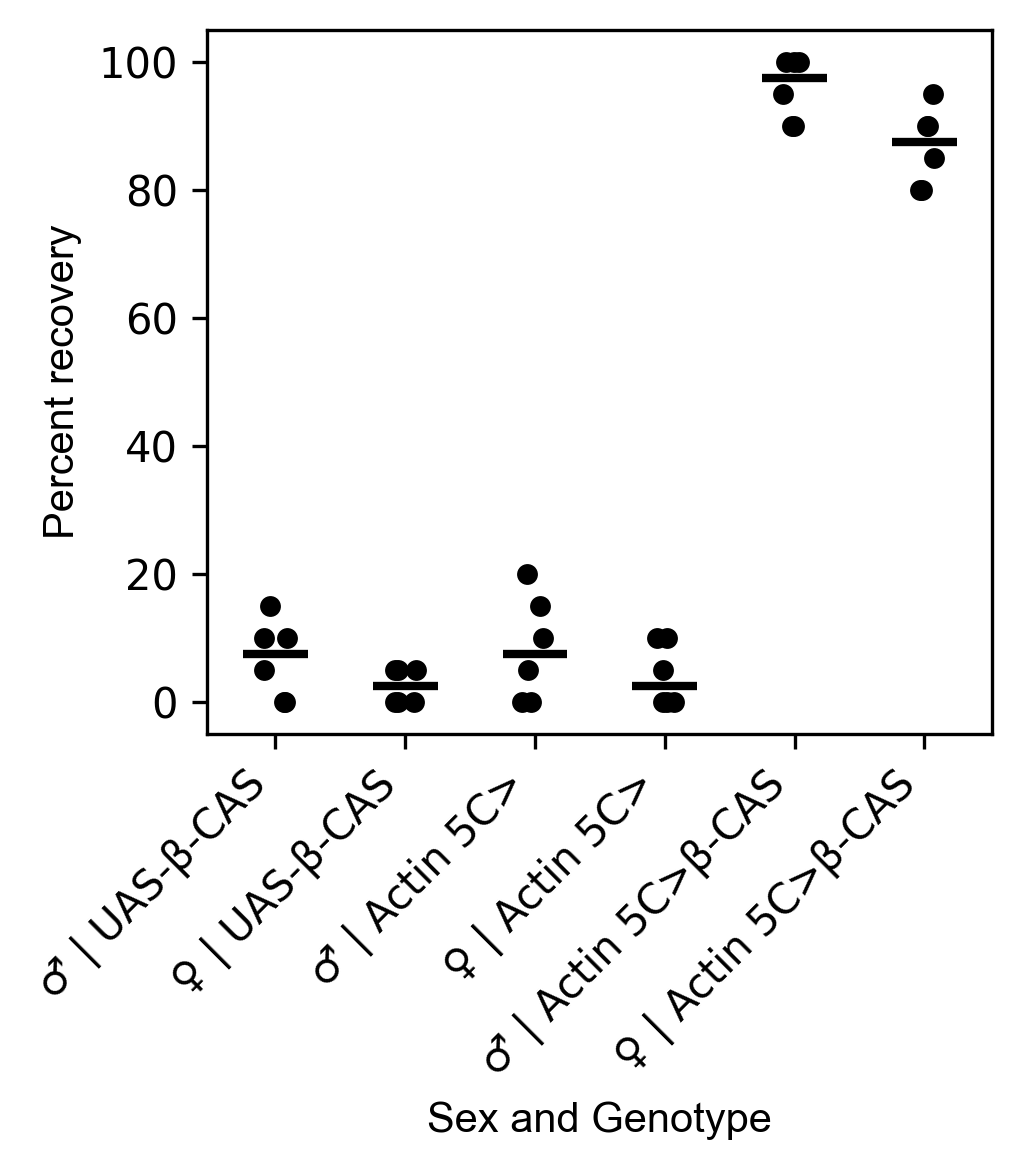

In [10]:
# Sex symbols
sex_map = {"Male": "♂", "Female": "♀", "M": "♂", "F": "♀"}
df["Sex"] = df["Sex"].map(sex_map).fillna(df["Sex"])

# --- Standardize the transgene name to β-CAS ---
# Add/adjust patterns here if your raw text varies.
df["Genotype"] = (df["Genotype"].astype(str)
                  .str.replace(r"Bcop\s*Cys\s*Synthase", "β-CAS", regex=True)
                  .str.replace(r"\bCys\s*Synthase\b", "β-CAS", regex=True))
##written by RK with chat-gpt
def pretty_genotype(g: str) -> str:
    g = g.strip()

    # Remove common trailing wildtype markers
    g = re.sub(r"\s*/\s*\+\s*$", "", g)      # "/+"
    g = re.sub(r"\s*\+\s*/\s*\+\s*$", "", g) # "+/+"

    if ">" in g:
        driver, cargo = [s.strip() for s in g.split(">", 1)]
        # if cargo contains β-CAS anywhere, just show β-CAS
        cargo = "β-CAS" if "β-CAS" in cargo else cargo
        return f"{driver}>{cargo}"

    # Otherwise it's slash-separated (e.g. UAS-... / act5c-...)
    parts = [p.strip() for p in g.split("/")]
    cleaned_parts = []
    for p in parts:
        # If this part contains β-CAS, keep a compact "SYSTEM-β-CAS" form when possible
        if "β-CAS" in p:
            # Keep the left "system" token (e.g. UAS) and attach β-CAS
            system = re.split(r"[-\s]", p, maxsplit=1)[0]
            cleaned_parts.append(f"{system}-β-CAS" if system else "β-CAS")
        else:
            # For drivers like "act5c-GAL4" -> "act5c"
            cleaned_parts.append(re.split(r"-", p)[0])

    return "/".join(cleaned_parts)

df["Genotype_pretty"] = df["Genotype"].apply(pretty_genotype)

# Combine
df["Sex_Genotype"] = df["Sex"].astype(str) + " | " + df["Genotype_pretty"]
order = list(df["Sex_Genotype"].dropna().unique())

# --- Plot ---
fig, ax = plt.subplots(figsize=(3.5, 4), dpi=300)

sns.stripplot(
    data=df,
    x="Sex_Genotype",
    y="Percent recovery",
    order=order,
    jitter=True,
    color="black",
    ax=ax
)

# Median lines
medians = (df.groupby("Sex_Genotype")['Percent recovery']
             .median()
             .reindex(order))

ax.hlines(
    y=medians.values,
    xmin=[i - 0.25 for i in range(len(order))],
    xmax=[i + 0.25 for i in range(len(order))],
    colors="black",
    linewidth=2,
    zorder=3
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("Percent recovery", fontname="Arial")
ax.set_xlabel("Sex and Genotype", fontname="Arial")
fig.tight_layout()

fig.savefig("figures/CN_percent_recovery.svg", format="svg")
plt.show()


In [11]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

## written by RK with chatgpt
TIME_COL = "Percent recovery"
SG_COL   = "Sex_Genotype"

# --- Define sex-genotype groups explicitly ---
groups = {
    "♂_combo": "♂ | Actin 5C>β-CAS",
    "♂_uas":   "♂ | UAS-β-CAS",
    "♂_act5c": "♂ | Actin 5C>",
    "♀_combo": "♀ | Actin 5C>β-CAS",
    "♀_uas":   "♀ | UAS-β-CAS",
    "♀_act5c": "♀ | Actin 5C>",
}

# --- Helper function ---
def mw_test(x, y, alternative="two-sided"):
    res = mannwhitneyu(x, y, alternative=alternative, method="auto")
    return float(res.statistic), float(res.pvalue)

results = []

comparisons = [
    ("♂_combo", "♂_uas"),
    ("♂_combo", "♂_act5c"),
    ("♀_combo", "♀_uas"),
    ("♀_combo", "♀_act5c"),
]

for g1, g2 in comparisons:
    x = df.loc[df[SG_COL] == groups[g1], TIME_COL].dropna().to_numpy()
    y = df.loc[df[SG_COL] == groups[g2], TIME_COL].dropna().to_numpy()

    if len(x) == 0 or len(y) == 0:
        results.append({
            "comparison": f"{groups[g1]} vs {groups[g2]}",
            "n1": len(x),
            "n2": len(y),
            "U": np.nan,
            "p": np.nan,
            'median_combo':np.median(x),
            'median_control':np.median(y),
            "note": "missing data"
        })
        continue

    U, p = mw_test(x, y)
    results.append({
        "comparison": f"{groups[g1]} vs {groups[g2]}",
        "n1": len(x),
        "n2": len(y),
        'median_combo':np.median(x),
        'median_control':np.median(y),   
        "U": U,
        "p": p
    })

res_df = pd.DataFrame(results)

# --- Optional: Benjamini–Hochberg FDR correction ---
def bh_fdr(p):
    p = np.asarray(p, dtype=float)
    mask = np.isfinite(p)
    ps = p[mask]
    m = len(ps)
    order = np.argsort(ps)
    q = ps[order] * m / (np.arange(1, m + 1))
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.full_like(p, np.nan)
    out[np.where(mask)[0][order]] = q
    return out

res_df["p_fdr_bh"] = bh_fdr(res_df["p"].values)

print(res_df.to_string(index=False))


                         comparison  n1  n2  median_combo  median_control    U        p  p_fdr_bh
♂ | Actin 5C>β-CAS vs ♂ | UAS-β-CAS   6   6          97.5             7.5 36.0 0.004551  0.004624
♂ | Actin 5C>β-CAS vs ♂ | Actin 5C>   6   6          97.5             7.5 36.0 0.004624  0.004624
♀ | Actin 5C>β-CAS vs ♀ | UAS-β-CAS   6   6          87.5             2.5 36.0 0.004337  0.004624
♀ | Actin 5C>β-CAS vs ♀ | Actin 5C>   6   6          87.5             2.5 36.0 0.004551  0.004624


## Redox (H2O2)

In [12]:
from lifelines import KaplanMeierFitter, CoxPHFitter

In [13]:
df=pd.read_csv("outputs/drosophila_experimental_data/H2O2_stress_tests - cumulative_daily_deaths.csv",index_col=0)

In [14]:
## days in which number of dead decreases from a previous day (errors)
day_cols = [c for c in df.columns if c.lower().startswith("day")]


for index, row in df.iterrows():
    deaths = [0] + [row[c] if not pd.isna(row[c]) else 25 for c in day_cols]
    for i in range(1,len(deaths)):
        if deaths[i]<deaths[i-1]:
            print(index,row['Genotype'],row['Treatment'],row['Sex'],row['Repeat'],day_cols[i],day_cols[i+1],deaths[i-1],deaths[i])

In [15]:
##number of flies in each vial at the beginning
START_N=25
# ---- CONVERT cumulative deaths → individual-level survival data ----
records = []
for _, row in df.iterrows():
    Genotype, Treatment, Sex, rep = row["Genotype"], row["Treatment"], row["Sex"], row["Repeat"]

    deaths_raw = row[day_cols].astype(float)

    # 1) Carry the last observed cumulative count forward
    deaths = deaths_raw.ffill()

    # 2) Stay within physical bounds and enforce monotonicity in deaths, accounting for the previously observed errors
    deaths = deaths.clip(0, START_N).cummax()

    # 3) Prepend Day 0 = 0 deaths
    deaths = [0]+list(deaths)
    # ensure cumulative non-decreasing
 
    # survivors each day
    surv = [START_N - d for d in deaths]

    # deaths per day (incremental)
    for day in range(1, int(len(surv))):
        died = max(0, surv[day-1] - surv[day])
        for _ in range(int(died)):
            records.append({
                "duration": float(day),
                "event": 1,
                "Genotype": Genotype,
                "Treatment": Treatment,
                "Sex": Sex,
                "Repeat": rep
            })


long_df = pd.DataFrame.from_records(records)
# long_df.dropna(subset=["Sex","Treatment","Genotype"], inplace=True)

long_df

,duration,event,Genotype,Treatment,Sex,Repeat
0,5.0,1,Actin5c>,1%suc,female,1
1,7.0,1,Actin5c>,1%suc,female,1
2,7.0,1,Actin5c>,1%suc,female,1
3,8.0,1,Actin5c>,1%suc,female,1
4,9.0,1,Actin5c>,1%suc,female,1
...,...,...,...,...,...,...
2494,3.0,1,Actin5c>Bcop Apex2,1%suc+1%h2o2,male,5
2495,3.0,1,Actin5c>Bcop Apex2,1%suc+1%h2o2,male,5
2496,3.0,1,Actin5c>Bcop Apex2,1%suc+1%h2o2,male,5
2497,4.0,1,Actin5c>Bcop Apex2,1%suc+1%h2o2,male,5


/tmp/ipykernel_3223164/4204802796.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfi['Sex_Genotype']=[x+"_"+y for x,y in zip(dfi.Sex,dfi.Genotype)]


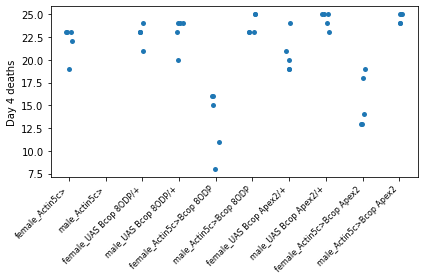

In [16]:
dfi=df[df.Treatment=='1%suc+1%h2o2']

dfi['Sex_Genotype']=[x+"_"+y for x,y in zip(dfi.Sex,dfi.Genotype)]
sns.stripplot(
    data=dfi,
    x="Sex_Genotype",
    y="Day 4",
    dodge=True
)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.xlabel("")
plt.ylabel("Day 4 deaths")
plt.tight_layout()
plt.show()

In [18]:
!mkdir figures/survival_curves

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=8ODP | Treatment=1%suc | Sex=female
  Medians (days): double=12.0, driver_only=11.0, uas_only=11.0
  LT90 (days): double=14.0, driver_only=12.0, uas_only=14.0
  Log-rank p-values (double vs ...): driver_only=5.493E-07, uas_only=1.616E-02



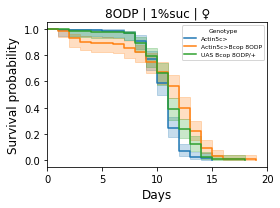

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=8ODP | Treatment=1%suc | Sex=male
  Medians (days): double=8.0, driver_only=7.0, uas_only=12.0
  LT90 (days): double=10.0, driver_only=10.0, uas_only=14.0
  Log-rank p-values (double vs ...): driver_only=1.441E-01, uas_only=1.175E-31



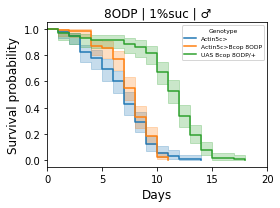

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=8ODP | Treatment=1%suc+1%h2o2 | Sex=female
  Medians (days): double=4.0, driver_only=4.0, uas_only=4.0
  LT90 (days): double=5.0, driver_only=5.0, uas_only=4.0
  Log-rank p-values (double vs ...): driver_only=1.073E-07, uas_only=3.521E-14



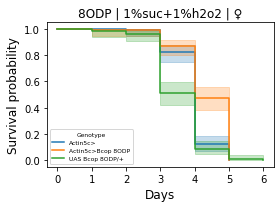

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=8ODP | Treatment=1%suc+1%h2o2 | Sex=male
  Medians (days): double=3.0, driver_only=3.0, uas_only=3.0
  LT90 (days): double=4.0, driver_only=3.0, uas_only=4.0
  Log-rank p-values (double vs ...): driver_only=3.678E-16, uas_only=1.206E-01



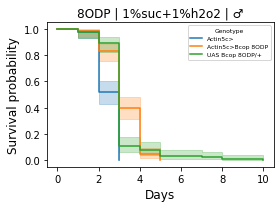

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=Apex2 | Treatment=1%suc | Sex=female
  Medians (days): double=11.0, driver_only=11.0, uas_only=11.0
  LT90 (days): double=14.0, driver_only=12.0, uas_only=12.0
  Log-rank p-values (double vs ...): driver_only=1.386E-03, uas_only=1.601E-04



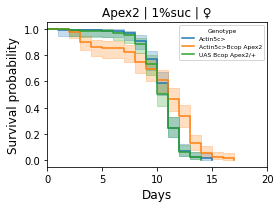

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=Apex2 | Treatment=1%suc | Sex=male
  Medians (days): double=8.0, driver_only=7.0, uas_only=10.0
  LT90 (days): double=10.0, driver_only=10.0, uas_only=12.0
  Log-rank p-values (double vs ...): driver_only=4.913E-03, uas_only=2.598E-21



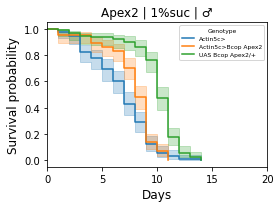

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=Apex2 | Treatment=1%suc+1%h2o2 | Sex=female
  Medians (days): double=4.0, driver_only=4.0, uas_only=4.0
  LT90 (days): double=5.0, driver_only=5.0, uas_only=5.0
  Log-rank p-values (double vs ...): driver_only=5.875E-04, uas_only=1.443E-04



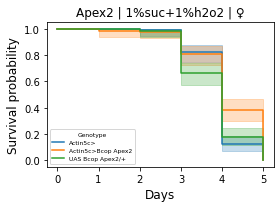

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=Apex2 | Treatment=1%suc+1%h2o2 | Sex=male
  Medians (days): double=3.0, driver_only=3.0, uas_only=3.0
  LT90 (days): double=4.0, driver_only=3.0, uas_only=4.0
  Log-rank p-values (double vs ...): driver_only=3.383E-19, uas_only=1.788E-01



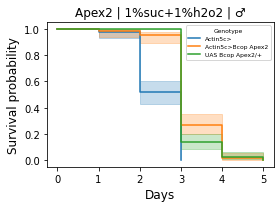

In [19]:
# --- imports ---
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

sex_map={'male':"♂", 'female': "♀"}
# ------------------------------------------------------------------
# Assumes you already have a long_df like:
# columns: ["Genotype", "Treatment", "Sex", "duration", "event", ...]
# duration: time in days; event: 1=death, 0=censored
# ------------------------------------------------------------------

# Helper: subset to Genotypes that contain the given transgene keyword (case-insensitive)
# and exclude the *other* transgene family.
def subset_by_transgene(df, keyword):
    d = set(["8ODP", "Apex2"])
    other = list(d - set([keyword]))[0]

    return df[~df.Genotype.str.contains(other, case=False, na=False)]

# Map Genotype strings into the three comparison groups for a given transgene keyword.
# - "Actin 5c>"               -> driver>only
# - "Actin5c>Bcop 8ODP"       -> double driver>transgene
# - "UAS Bcop 8ODP/+"         -> UAS only
def categorize_groups(s, tg):

    # driver>only: driver name present, ends with '>', no UAS, no transgene token
    driver_only_mask = s=='Actin5c>'
    # UAS only: has 'uas' + the transgene token, but no driver token
    uas_only_mask = (
        s.str.contains('UAS')
        & s.str.contains(tg)
    )

    # double driver>transgene: has driver + '>' + the transgene token, not "only"
    double_mask = (
        s.str.contains("Actin5c")
        & s.str.contains("Bcop")
        & s.str.contains(tg)
       
    )

    grp = pd.Series(index=s.index, dtype="object")
    grp[double_mask] = "double_driver>transgene"
    grp[driver_only_mask] = "driver>only"
    grp[uas_only_mask] = "uas only"
    print(set(grp))
    return grp

# Pretty formatter for p-values
from decimal import Decimal

def fmt_p(p):
    return '%.3E' % Decimal(str(p))

# --- NEW: tiny helper to read LT90 off a fitted KMF ---
def time_to_fraction_death_from_kmf(kmf, frac=0.9):
    """
    Return earliest time when survival <= (1 - frac).
    Example: frac=0.9 -> time to 90% death (survival <= 0.1).
    """
    surv = kmf.survival_function_.iloc[:, 0]
    threshold = 1 - frac  # 0.1 for 90% death
    hits = surv[surv <= threshold]
    if hits.empty:
        return np.nan
    return float(hits.index[0])

# Your transgene identifiers to look for in Genotype names
transgenes = ["8ODP", "Apex2"]

# Optional: match your axis label font preference
global_tests=[]

# --- main loop ---
for tg in transgenes:
    df_tg = subset_by_transgene(long_df, tg)
    if df_tg.empty:
        print(f"No Genotypes found for {tg}.")
        continue

    # Split by Treatment × Sex
    for (trt, Sex), df_sub in df_tg.groupby(["Treatment", "Sex"], observed=True):
        if df_sub.empty:
            continue

        # Assign comparison groups based on Genotype strings
        df_sub = df_sub.copy()
        df_sub["cmp_group"] = categorize_groups(df_sub["Genotype"], tg)

        # keep only three groups of interest
        keep = df_sub["cmp_group"].isin(["double_driver>transgene", "driver>only", "uas only"])
        df_cmp = df_sub[keep].copy()

        if df_cmp.empty or df_cmp["cmp_group"].nunique() < 2:
            print(f"[{tg} | {trt} | {Sex}] Not enough comparison groups found.")
            continue

        plt.figure(figsize=(4, 3))
        kmf = KaplanMeierFitter()

        # Plot KM for each *Genotype line*
        plotted_any = False
        for geno, df_geno in df_sub.groupby("Genotype", observed=True):
            if df_geno.empty:
                continue
            kmf.fit(
                durations=df_geno["duration"],
                event_observed=df_geno["event"],
                label=str(geno)
            )
            kmf.plot(ci_show=True, show_censors=True)  # CI + censor marks
            plotted_any = True

        if not plotted_any:
            plt.close()
            print(f"[{tg} | {trt} | {Sex}] Nothing to plot.")
            continue

        # Compute medians (existing) and --- NEW: LT90 --- using the three *comparison buckets*
        medians = {}
        lt90 = {}  # NEW
        groups_data = {}

        for gname, df_g in df_cmp.groupby("cmp_group", observed=True):
            
            durations = df_g["duration"].to_numpy()
            events = df_g["event"].to_numpy()
            # fit once to get median and LT90
            kmf.fit(durations=durations, event_observed=events)
            medians[gname] = kmf.median_survival_time_
           
            lt90[gname] = time_to_fraction_death_from_kmf(kmf, frac=0.9)  # NEW
            groups_data[gname] = (durations, events)

        # Pairwise log-rank: double vs driver-only; double vs UAS-only
        p_double_vs_driver = None
        p_double_vs_uas = None

        if "double_driver>transgene" in groups_data and "driver>only" in groups_data:
            d_dur, d_evt = groups_data["double_driver>transgene"]
            dr_dur, dr_evt = groups_data["driver>only"]
            if len(d_dur) > 0 and len(dr_dur) > 0:
                res = logrank_test(d_dur, dr_dur, event_observed_A=d_evt, event_observed_B=dr_evt, alpha=0.95)
                p_double_vs_driver = res.p_value
           

        if "double_driver>transgene" in groups_data and "uas only" in groups_data:
            d_dur, d_evt = groups_data["double_driver>transgene"]
            u_dur, u_evt = groups_data["uas only"]
            if len(d_dur) > 0 and len(u_dur) > 0:
                res = logrank_test(d_dur, u_dur, event_observed_A=d_evt, event_observed_B=u_evt, alpha=0.95)
                p_double_vs_uas = res.p_value


        # Labeling and titles
        if trt=='1%suc':
            plt.xlim(0,20)
        plt.xlabel("Days", fontsize=12)
        plt.ylabel("Survival probability", fontsize=12)
        plt.title(f"{tg} | {trt} | {sex_map[Sex]}")

    
        ax = plt.gca()

        plt.legend(title="Genotype", fontsize=6, title_fontsize=6, loc="best")
        plt.tight_layout()
  
         # Build annotation text (unchanged medians + NEW LT90 block)
        med_dd = medians.get("double_driver>transgene", np.nan)
        med_do = medians.get("driver>only", np.nan)
        med_uo = medians.get("uas only", np.nan)

        lt90_dd = lt90.get("double_driver>transgene", np.nan)  # NEW
        lt90_do = lt90.get("driver>only", np.nan)              # NEW
        lt90_uo = lt90.get("uas only", np.nan)                 # NEW
        # Also print a compact summary to stdout for logging (add LT90s)
        print(f"[KM SUMMARY] Transgene={tg} | Treatment={trt} | Sex={Sex}")
        print("  Medians (days): "
              f"double={np.nan if pd.isna(med_dd) else round(float(med_dd), 2)}, "
              f"driver_only={np.nan if pd.isna(med_do) else round(float(med_do), 2)}, "
              f"uas_only={np.nan if pd.isna(med_uo) else round(float(med_uo), 2)}")
        print("  LT90 (days): "  # NEW
              f"double={np.nan if pd.isna(lt90_dd) else round(float(lt90_dd), 2)}, "
              f"driver_only={np.nan if pd.isna(lt90_do) else round(float(lt90_do), 2)}, "
              f"uas_only={np.nan if pd.isna(lt90_uo) else round(float(lt90_uo), 2)}")
        print("  Log-rank p-values (double vs ...): "
              f"driver_only={fmt_p(p_double_vs_driver)}, "
              f"uas_only={fmt_p(p_double_vs_uas)}\n")

        plt.savefig(f"figures/survival_curves/KM_{tg}_{trt}_{Sex}.svg",format='svg')
        plt.show()
        plt.close()


In [74]:
!pip show lifelines

Name: lifelines
Version: 0.30.0
Summary: Survival analysis in Python, including Kaplan Meier, Nelson Aalen and regression
Home-page: https://github.com/CamDavidsonPilon/lifelines
Author: Cameron Davidson-Pilon
Author-email: cam.davidson.pilon@gmail.com
License: MIT
Location: /n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages
Requires: autograd, matplotlib, numpy, scipy, autograd-gamma, formulaic, pandas
Required-by: 


In [20]:
set(long_df.Genotype)

{'Actin5c>',
 'Actin5c>Bcop 8ODP',
 'Actin5c>Bcop Apex2',
 'UAS Bcop 8ODP/+',
 'UAS Bcop Apex2/+'}

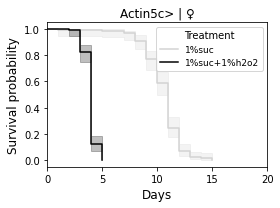

[KM SUMMARY] Genotype=Actin5c> | Sex=female
  Median lifespan (days):
    1%suc               : 11.0
    1%suc+1%h2o2        : 4.0
  Time to 90% death (LT90, days):
    1%suc               : 12.0
    1%suc+1%h2o2        : 5.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




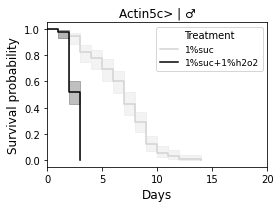

[KM SUMMARY] Genotype=Actin5c> | Sex=male
  Median lifespan (days):
    1%suc               : 7.0
    1%suc+1%h2o2        : 3.0
  Time to 90% death (LT90, days):
    1%suc               : 10.0
    1%suc+1%h2o2        : 3.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




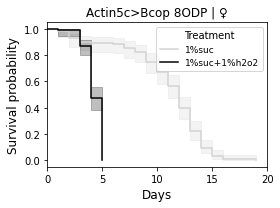

[KM SUMMARY] Genotype=Actin5c>Bcop 8ODP | Sex=female
  Median lifespan (days):
    1%suc               : 12.0
    1%suc+1%h2o2        : 4.0
  Time to 90% death (LT90, days):
    1%suc               : 14.0
    1%suc+1%h2o2        : 5.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




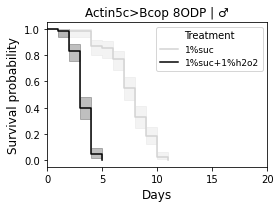

[KM SUMMARY] Genotype=Actin5c>Bcop 8ODP | Sex=male
  Median lifespan (days):
    1%suc               : 8.0
    1%suc+1%h2o2        : 3.0
  Time to 90% death (LT90, days):
    1%suc               : 10.0
    1%suc+1%h2o2        : 4.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




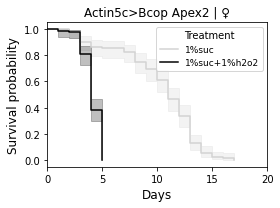

[KM SUMMARY] Genotype=Actin5c>Bcop Apex2 | Sex=female
  Median lifespan (days):
    1%suc               : 11.0
    1%suc+1%h2o2        : 4.0
  Time to 90% death (LT90, days):
    1%suc               : 14.0
    1%suc+1%h2o2        : 5.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




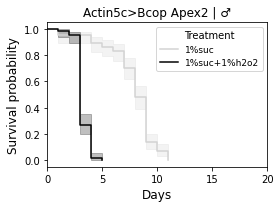

[KM SUMMARY] Genotype=Actin5c>Bcop Apex2 | Sex=male
  Median lifespan (days):
    1%suc               : 8.0
    1%suc+1%h2o2        : 3.0
  Time to 90% death (LT90, days):
    1%suc               : 10.0
    1%suc+1%h2o2        : 4.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




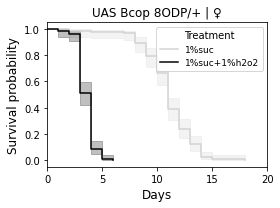

[KM SUMMARY] Genotype=UAS Bcop 8ODP/+ | Sex=female
  Median lifespan (days):
    1%suc               : 11.0
    1%suc+1%h2o2        : 4.0
  Time to 90% death (LT90, days):
    1%suc               : 14.0
    1%suc+1%h2o2        : 4.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




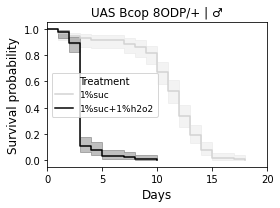

[KM SUMMARY] Genotype=UAS Bcop 8ODP/+ | Sex=male
  Median lifespan (days):
    1%suc               : 12.0
    1%suc+1%h2o2        : 3.0
  Time to 90% death (LT90, days):
    1%suc               : 14.0
    1%suc+1%h2o2        : 4.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




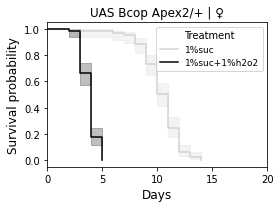

[KM SUMMARY] Genotype=UAS Bcop Apex2/+ | Sex=female
  Median lifespan (days):
    1%suc               : 11.0
    1%suc+1%h2o2        : 4.0
  Time to 90% death (LT90, days):
    1%suc               : 12.0
    1%suc+1%h2o2        : 5.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




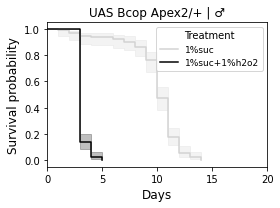

[KM SUMMARY] Genotype=UAS Bcop Apex2/+ | Sex=male
  Median lifespan (days):
    1%suc               : 10.0
    1%suc+1%h2o2        : 3.0
  Time to 90% death (LT90, days):
    1%suc               : 12.0
    1%suc+1%h2o2        : 4.0
  Pairwise log-rank p-values:
    1%suc  vs  1%suc+1%h2o2: p = <1e-4




In [21]:
# One plot per Genotype × Sex; within each plot, curves for all Treatments
cmap={'1%suc+1%h2o2':'#000000', '1%suc':'#D3D3D3'}
for geno, df_g in long_df.groupby("Genotype", observed=True):
    for Sex, df_gs in df_g.groupby("Sex", observed=True):
        if df_gs.empty:
            continue

   
        kmf = KaplanMeierFitter()

        medians = {}
        lt90 = {}
        plt.figure(figsize=(4, 3))
        # fit and plot per Treatment
        for trt, df_gst in df_gs.groupby("Treatment", observed=True):
            if df_gst.empty:
                continue
            kmf.fit(
                durations=df_gst["duration"],
                event_observed=df_gst["event"],
                label=str(trt),
            )
            kmf.plot(ci_show=True, show_censors=True, color=cmap[trt])
            medians[trt] = kmf.median_survival_time_
            lt90[trt] = time_to_fraction_death_from_kmf(kmf, frac=0.9)

        # figure labeling
        plt.xlabel("Days")
        plt.ylabel("Survival probability")
        plt.xlabel("Days", fontsize=12)
        plt.ylabel("Survival probability", fontsize=12)
        plt.title(f"{geno} | {sex_map[Sex]}")
        plt.xlim(0,20)

        plt.legend(title="Treatment", fontsize=9, title_fontsize=10, loc="best")
        plt.tight_layout()
        g=geno.replace("/","")
        if 'Actin5c>Bcop' in g:
            plt.savefig(f"figures/survival_curves/KM_treatment_{g}_{Sex}.svg",format='svg')
        plt.show()

        # --- Pairwise log-rank tests across Treatments in this panel ---
        # Build data dict for quick access
        trt_groups = {}
        for trt, df_gst in df_gs.groupby("Treatment", observed=True):
            if not df_gst.empty:
                trt_groups[trt] = (
                    df_gst["duration"].to_numpy(),
                    df_gst["event"].to_numpy()
                )

        # all unique pairs
        trts = list(trt_groups.keys())
        pairs = []
        pvals = []
        for i in range(len(trts)):
            for j in range(i + 1, len(trts)):
                a, b = trts[i], trts[j]
                dur_a, evt_a = trt_groups[a]
                dur_b, evt_b = trt_groups[b]
                if len(dur_a) == 0 or len(dur_b) == 0:
                    p = np.nan
                else:
                    res = logrank_test(dur_a, dur_b, event_observed_A=evt_a, event_observed_B=evt_b, alpha=0.95)
                    p = float(res.p_value) if np.isfinite(res.p_value) else np.nan
                pairs.append((a, b))
                pvals.append(p)
        pvals = np.array(pvals, dtype=float)
        

        # --- print summary for this Genotype × Sex ---
        print(f"[KM SUMMARY] Genotype={geno} | Sex={Sex}")
        print("  Median lifespan (days):")
        for trt in trts:
            m = medians.get(trt, np.nan)
            print(f"    {str(trt):20s}: {np.nan if pd.isna(m) else round(float(m), 2)}")
        print("  Time to 90% death (LT90, days):")
        for trt in trts:
            l = lt90.get(trt, np.nan)
            print(f"    {str(trt):20s}: {np.nan if pd.isna(l) else round(float(l), 2)}")

        print("  Pairwise log-rank p-values:")
        if len(pairs) == 0:
            print("    (no comparable Treatment pairs)")
        else:
            for (a, b), p_raw in zip(pairs, pvals):
           
                p_raw_str = "<1e-4" if (isinstance(p_raw, float) and p_raw < 1e-4) else ( "NA" if (not np.isfinite(p_raw)) else f"{p_raw:.3g}" )
                print(f"    {a}  vs  {b}: p = {p_raw_str}")
        print("\n")
      

In [22]:
from lifelines import CoxPHFitter

## H2O2 effect

In [23]:
dfm = long_df.copy()

dfm["Genotype"] = pd.Categorical(dfm["Genotype"], categories=['Actin5c>',
 'Actin5c>Bcop 8ODP',
 'Actin5c>Bcop Apex2',
 'UAS Bcop 8ODP/+',
 'UAS Bcop Apex2/+'], ordered=False)
dfm["Sex"] = pd.Categorical(dfm["Sex"], categories=["male","female"], ordered=False)
dfm["Treatment"] = pd.Categorical(dfm["Treatment"], categories=['1%suc', '1%suc+1%h2o2'], ordered=False)
dfm["Sex"] = pd.Categorical(dfm["Sex"], categories=["male","female"], ordered=False)
# --- 2) Fit Cox PH 
cph = CoxPHFitter() 
cph.fit(
    dfm,
    duration_col="duration",
    event_col="event",
    formula="Treatment + Genotype + Sex",  
    cluster_col="Repeat",   
    robust=True
)

# View results (coefficients, HRs, p-values, CIs)
cph.summary

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
Treatment[T.1%suc+1%h2o2],3.574152,35.664367,0.080808,3.415772,3.732532,30.440436,41.784786,0.0,44.230327,0.000000e+00,inf
Genotype[T.Actin5c>Bcop 8ODP],-0.561455,0.570378,0.120279,-0.797197,-0.325714,0.450590,0.722012,0.0,-4.667959,3.042072e-06,18.326514
Genotype[T.Actin5c>Bcop Apex2],-0.436960,0.645997,0.291132,-1.007568,0.133648,0.365106,1.142990,0.0,-1.500901,1.333812e-01,2.906373
Genotype[T.UAS Bcop 8ODP/+],-0.872359,0.417964,0.166791,-1.199264,-0.545454,0.301416,0.579579,0.0,-5.230239,1.692910e-07,22.493991
Genotype[T.UAS Bcop Apex2/+],-0.460377,0.631046,0.183659,-0.820342,-0.100411,0.440281,0.904466,0.0,-2.506688,1.218682e-02,6.358534
Sex[T.female],-0.877282,0.415912,0.071654,-1.017721,-0.736843,0.361418,0.478622,0.0,-12.243342,1.823648e-34,112.078728


In [24]:

## make df of pairwise cox ph results stratified by sex and treatment
import pandas as pd
import numpy as np
from lifelines import CoxPHFitter

treatments = list(set(long_df.Treatment))
sexes = list(set(long_df.Sex))




def run_cox_for_subset(df_subset: pd.DataFrame, base_genotype: str, other):
    """
    Fit Cox PH with Genotype as categorical and a chosen reference (base_genotype).
    Returns a list of dict rows (one per non-reference genotype level in the model).
    """
    
    df_subset["Genotype"] = pd.Categorical(df_subset["Genotype"], categories=[base_genotype, other], ordered=False)
    cph = CoxPHFitter()
    cph.fit(
        df_subset,
        duration_col="duration",
        event_col="event",
        formula='Genotype',
        cluster_col="Repeat",
        robust=True
    )

    r = cph.summary

    out_rows={"Comparison": f"{other} vs {base_genotype}", "HR": r["exp(coef)"].values[0], "HR 95% CI (lower)": r["exp(coef) lower 95%"].values[0], "HR 95% CI (upper)": r["exp(coef) upper 95%"].values[0], "p-value": r["p"].values[0]}

    return out_rows

results = []

transgenes=set(['Apex2', '8ODP'])
for tg in transgenes:
    bases = [f"UAS Bcop {tg}/+", "Actin5c>"]
    for treatment in treatments:
        for sex in sexes:
            for base in bases:
                try:
                    
                    df_subset = long_df[ (long_df["Treatment"] == treatment) & (long_df["Sex"] == sex) & ~(long_df['Genotype'].isin(set(bases)-set([base]))) & ~(long_df['Genotype'].str.contains(list(transgenes-set([tg]))[0]))].copy()
              
                    row = run_cox_for_subset(df_subset, base, f'Actin5c>Bcop {tg}')
                    row.update({"Treatment": treatment, "Sex": sex, "Base": base})
                    results.append(row)
                except Exception as e:
                    # If a model fails (e.g., complete separation / zero events), record a row noting failure
                    results.append({
                        "Comparison": f"(model failed) vs base={base}",
                        "Treatment": treatment,
                        "Sex": sex,
                        "Base": base,
                        "HR": np.nan,
                        "HR 95% CI (lower)": np.nan,
                        "HR 95% CI (upper)": np.nan,
                        "p-value": np.nan,
                        "error": str(e),
                    })

results_df = pd.DataFrame(results)


col_order = ["Comparison", "Treatment", "Sex", "Base", "HR", "HR 95% CI (lower)", "HR 95% CI (upper)", "p-value"]


results_df=results_df.loc[:, col_order]


In [25]:
display_df = results_df.copy()

display_df["HR"] = display_df["HR"].map(lambda x: f"{x:.2f}")
display_df["HR 95% CI (lower)"] = display_df["HR 95% CI (lower)"].map(lambda x: f"{x:.2f}")
display_df["HR 95% CI (upper)"] = display_df["HR 95% CI (upper)"].map(lambda x: f"{x:.2f}")
display_df["p-value"] = display_df["p-value"].map(lambda x: f"{x:.2e}")
display_df.drop('Base',axis=1)

,Comparison,Treatment,Sex,HR,HR 95% CI (lower),HR 95% CI (upper),p-value
0,Actin5c>Bcop 8ODP vs UAS Bcop 8ODP/+,1%suc+1%h2o2,male,0.78,0.47,1.30,3.43e-01
1,Actin5c>Bcop 8ODP vs Actin5c>,1%suc+1%h2o2,male,0.28,0.13,0.61,1.29e-03
2,Actin5c>Bcop 8ODP vs UAS Bcop 8ODP/+,1%suc+1%h2o2,female,0.43,0.26,0.73,1.70e-03
3,Actin5c>Bcop 8ODP vs Actin5c>,1%suc+1%h2o2,female,0.52,0.27,1.00,4.89e-02
4,Actin5c>Bcop 8ODP vs UAS Bcop 8ODP/+,1%suc,male,7.98,4.50,14.17,1.28e-12
5,Actin5c>Bcop 8ODP vs Actin5c>,1%suc,male,0.89,0.36,2.20,7.92e-01
6,Actin5c>Bcop 8ODP vs UAS Bcop 8ODP/+,1%suc,female,0.72,0.47,1.09,1.17e-01
7,Actin5c>Bcop 8ODP vs Actin5c>,1%suc,female,0.48,0.28,0.81,5.71e-03
8,Actin5c>Bcop Apex2 vs UAS Bcop Apex2/+,1%suc+1%h2o2,male,0.83,0.41,1.66,5.93e-01
9,Actin5c>Bcop Apex2 vs Actin5c>,1%suc+1%h2o2,male,0.32,0.13,0.80,1.56e-02


In [26]:
df_subset 

,duration,event,Genotype,Treatment,Sex,Repeat
0,5.0,1,Actin5c>,1%suc,female,1
1,7.0,1,Actin5c>,1%suc,female,1
2,7.0,1,Actin5c>,1%suc,female,1
3,8.0,1,Actin5c>,1%suc,female,1
4,9.0,1,Actin5c>,1%suc,female,1
...,...,...,...,...,...,...
2119,13.0,1,Actin5c>Bcop Apex2,1%suc,female,5
2120,13.0,1,Actin5c>Bcop Apex2,1%suc,female,5
2121,13.0,1,Actin5c>Bcop Apex2,1%suc,female,5
2122,13.0,1,Actin5c>Bcop Apex2,1%suc,female,5


## Arsenite Methyltransferase

In [27]:
df=pd.read_csv("outputs/drosophila_experimental_data/ArsMeth_ArsenicToxicityExpt.csv")

In [28]:
## days in which number of dead decreases from a previous day (errors)
day_cols = [c for c in df.columns if c.lower().startswith("day")]

errors=[]
for index, row in df.iterrows():
    deaths = [0] + [row[c] if not pd.isna(row[c]) else 25 for c in day_cols]
    for i in range(1,len(deaths)):
        if deaths[i]<deaths[i-1]:
            print(index,row['Genotype'],row['Treatment'],row['Sex'],row['Repeat'],day_cols[i],day_cols[i-1],deaths[i],deaths[i-1])
            errors.append(index)

8 Actin5c> 1µM Arsenic + 4-24 Diet Female 2 Day 10 Day 9 0 1
84 Actin5c>Bcop ArsM 1µM Arsenic + 4-24 Diet Male 6 Day 14 Day 13 21 22


In [29]:
errors

[8, 84]

In [30]:
last_day=float(day_cols[-1].split(" ")[-1])
##number of flies in each vial at the beginning
START_N=25
# ---- CONVERT cumulative deaths → individual-level survival data ----
records = []
for _, row in df.iterrows():
    Genotype, Treatment, Sex, rep = row["Genotype"], row["Treatment"], row["Sex"], row["Repeat"]

    deaths_raw = row[day_cols].astype(float)

    # 1) Carry the last observed cumulative count forward
    deaths = deaths_raw.ffill()

    # 2) Stay within physical bounds and enforce monotonicity in deaths, accounting for the previously observed errors
    deaths = deaths.clip(0, START_N).cummax()

    # 3) Prepend Day 0 = 0 deaths
    deaths = [0]+list(deaths)
    # ensure cumulative non-decreasing
 
    # survivors each day
    surv = [START_N - d for d in deaths]

    # deaths per day (incremental)
    for day in range(1, int(len(surv))):
        died = max(0, surv[day-1] - surv[day])
        for _ in range(int(died)):
            records.append({
                "duration": float(day),
                "event": 1,
                "Genotype": Genotype,
                "Treatment": Treatment,
                "Sex": Sex,
                "Repeat": rep
            })
    # right-censor remaining flies
    for _ in range(int(max(0, surv[-1]))):
        records.append({
            "duration": last_day,
            "event": 0,
            "Genotype": Genotype,
            "Treatment": Treatment,
            "Sex": Sex,
            "Repeat": rep
        })


long_df = pd.DataFrame.from_records(records)
# long_df.dropna(subset=["Sex","Treatment","Genotype"], inplace=True)

long_df

,duration,event,Genotype,Treatment,Sex,Repeat
0,3.0,1,Actin5c>,4-24 Diet,Female,1
1,18.0,1,Actin5c>,4-24 Diet,Female,1
2,18.0,0,Actin5c>,4-24 Diet,Female,1
3,18.0,0,Actin5c>,4-24 Diet,Female,1
4,18.0,0,Actin5c>,4-24 Diet,Female,1
...,...,...,...,...,...,...
2170,12.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8
2171,12.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8
2172,15.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8
2173,16.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8


In [31]:
last_day=float(day_cols[-1].split(" ")[-1])
##number of flies in each vial at the beginning
START_N=25
# ---- CONVERT cumulative deaths → individual-level survival data, excluding error rows ----
records = []
for _, row in df[~df.index.isin([8,84])].iterrows():
    Genotype, Treatment, Sex, rep = row["Genotype"], row["Treatment"], row["Sex"], row["Repeat"]

    deaths_raw = row[day_cols].astype(float)

    # 1) Carry the last observed cumulative count forward
    deaths = deaths_raw.ffill()

    # 2) Stay within physical bounds and enforce monotonicity in deaths, accounting for the previously observed errors
    deaths = deaths.clip(0, START_N).cummax()

    # 3) Prepend Day 0 = 0 deaths
    deaths = [0]+list(deaths)
    # ensure cumulative non-decreasing
 
    # survivors each day
    surv = [START_N - d for d in deaths]

    # deaths per day (incremental)
    for day in range(1, int(len(surv))):
        died = max(0, surv[day-1] - surv[day])
        for _ in range(int(died)):
            records.append({
                "duration": float(day),
                "event": 1,
                "Genotype": Genotype,
                "Treatment": Treatment,
                "Sex": Sex,
                "Repeat": rep
            })
    # right-censor remaining flies
    for _ in range(int(max(0, surv[-1]))):
        records.append({
            "duration": last_day,
            "event": 0,
            "Genotype": Genotype,
            "Treatment": Treatment,
            "Sex": Sex,
            "Repeat": rep
        })


long_df_filtered = pd.DataFrame.from_records(records)
# long_df.dropna(subset=["Sex","Treatment","Genotype"], inplace=True)

long_df_filtered

,duration,event,Genotype,Treatment,Sex,Repeat
0,3.0,1,Actin5c>,4-24 Diet,Female,1
1,18.0,1,Actin5c>,4-24 Diet,Female,1
2,18.0,0,Actin5c>,4-24 Diet,Female,1
3,18.0,0,Actin5c>,4-24 Diet,Female,1
4,18.0,0,Actin5c>,4-24 Diet,Female,1
...,...,...,...,...,...,...
2120,12.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8
2121,12.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8
2122,15.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8
2123,16.0,1,Actin5c>Bcop ArsM,1µM Arsenic + 4-24 Diet,Male,8


{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=ArsM | Treatment=1µM Arsenic + 4-24 Diet | Sex=Female
  Medians (days): double=12.0, driver_only=11.0, uas_only=11.0
  LT90 (days): double=16.0, driver_only=12.0, uas_only=14.0
  Log-rank p-values (double vs ...): driver_only=4.310E-17, uas_only=8.037E-11



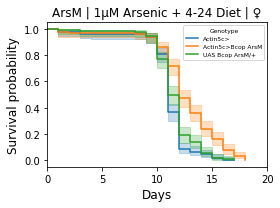

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=ArsM | Treatment=1µM Arsenic + 4-24 Diet | Sex=Male
  Medians (days): double=12.0, driver_only=10.0, uas_only=10.0
  LT90 (days): double=15.0, driver_only=11.0, uas_only=11.0
  Log-rank p-values (double vs ...): driver_only=2.056E-21, uas_only=1.177E-32



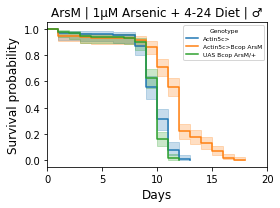

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=ArsM | Treatment=4-24 Diet | Sex=Female
  Medians (days): double=inf, driver_only=inf, uas_only=inf
  LT90 (days): double=nan, driver_only=nan, uas_only=nan
  Log-rank p-values (double vs ...): driver_only=1.019E-02, uas_only=6.618E-06



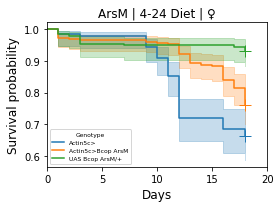

{'double_driver>transgene', 'driver>only', 'uas only'}
[KM SUMMARY] Transgene=ArsM | Treatment=4-24 Diet | Sex=Male
  Medians (days): double=inf, driver_only=inf, uas_only=inf
  LT90 (days): double=nan, driver_only=nan, uas_only=nan
  Log-rank p-values (double vs ...): driver_only=5.384E-01, uas_only=6.972E-01



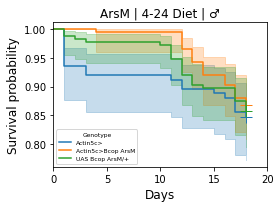

In [32]:
# --- imports ---
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

sex_map={'Male':"♂", 'Female': "♀"}
# ------------------------------------------------------------------
# Assumes you already have a long_df like:
# columns: ["Genotype", "Treatment", "Sex", "duration", "event", ...]
# duration: time in days; event: 1=death, 0=censored
# ------------------------------------------------------------------


# Map Genotype strings into the three comparison groups for a given transgene keyword.
# - "Actin 5c>"               -> driver>only
# - "Actin5c>Bcop 8ODP"       -> double driver>transgene
# - "UAS Bcop 8ODP/+"         -> UAS only
def categorize_groups(s, tg):

    # driver>only: driver name present, ends with '>', no UAS, no transgene token
    driver_only_mask = s=='Actin5c>'
    # UAS only: has 'uas' + the transgene token, but no driver token
    uas_only_mask = (
        s.str.contains('UAS')
    )

    # double driver>transgene: has driver + '>' + the transgene token, not "only"
    double_mask = (
        s.str.contains("Actin5c")
        & s.str.contains("Bcop")
       
    )

    grp = pd.Series(index=s.index, dtype="object")
    grp[double_mask] = "double_driver>transgene"
    grp[driver_only_mask] = "driver>only"
    grp[uas_only_mask] = "uas only"
    print(set(grp))
    return grp

# Pretty formatter for p-values
from decimal import Decimal

def fmt_p(p):
    return '%.3E' % Decimal(str(p))

# --- NEW: tiny helper to read LT90 off a fitted KMF ---
def time_to_fraction_death_from_kmf(kmf, frac=0.9):
    """
    Return earliest time when survival <= (1 - frac).
    Example: frac=0.9 -> time to 90% death (survival <= 0.1).
    """
    surv = kmf.survival_function_.iloc[:, 0]
    threshold = 1 - frac  # 0.1 for 90% death
    hits = surv[surv <= threshold]
    if hits.empty:
        return np.nan
    return float(hits.index[0])


# Optional: match your axis label font preference
global_tests=[]
tg='ArsM'
df_tg = long_df


# Split by Treatment × Sex
for (trt, Sex), df_sub in df_tg.groupby(["Treatment", "Sex"], observed=True):

    # Assign comparison groups based on Genotype strings
    df_sub = df_sub.copy()
    df_sub["cmp_group"] = categorize_groups(df_sub["Genotype"], tg)

    # keep only three groups of interest
    keep = df_sub["cmp_group"].isin(["double_driver>transgene", "driver>only", "uas only"])
    df_cmp = df_sub[keep].copy()


    plt.figure(figsize=(4, 3))
    kmf = KaplanMeierFitter()

    # Plot KM for each *Genotype line* (as in your original code)
    plotted_any = False
    for geno, df_geno in df_sub.groupby("Genotype", observed=True):
        if df_geno.empty:
            continue
        kmf.fit(
            durations=df_geno["duration"],
            event_observed=df_geno["event"],
            label=str(geno)
        )
        kmf.plot(ci_show=True, show_censors=True)  # CI + censor marks
        plotted_any = True

    # Compute medians (existing) and --- NEW: LT90 --- using the three *comparison buckets*
    medians = {}
    lt90 = {}  # NEW
    groups_data = {}

    for gname, df_g in df_cmp.groupby("cmp_group", observed=True):

        durations = df_g["duration"].to_numpy()
        events = df_g["event"].to_numpy()
        # fit once to get median and LT90
        kmf.fit(durations=durations, event_observed=events)
        medians[gname] = kmf.median_survival_time_

        lt90[gname] = time_to_fraction_death_from_kmf(kmf, frac=0.9)  # NEW
        groups_data[gname] = (durations, events)

    # Pairwise log-rank: double vs driver-only; double vs UAS-only
    p_double_vs_driver = None
    p_double_vs_uas = None

    if "double_driver>transgene" in groups_data and "driver>only" in groups_data:
        d_dur, d_evt = groups_data["double_driver>transgene"]
        dr_dur, dr_evt = groups_data["driver>only"]
        if len(d_dur) > 0 and len(dr_dur) > 0:
            res = logrank_test(d_dur, dr_dur, event_observed_A=d_evt, event_observed_B=dr_evt, alpha=0.95)
            p_double_vs_driver = res.p_value


    if "double_driver>transgene" in groups_data and "uas only" in groups_data:
        d_dur, d_evt = groups_data["double_driver>transgene"]
        u_dur, u_evt = groups_data["uas only"]
        if len(d_dur) > 0 and len(u_dur) > 0:
            res = logrank_test(d_dur, u_dur, event_observed_A=d_evt, event_observed_B=u_evt, alpha=0.95)
            p_double_vs_uas = res.p_value


    # Labeling and titles
    plt.xlabel("Days", fontsize=12)
    plt.ylabel("Survival probability", fontsize=12)
    plt.title(f"{tg} | {trt} | {sex_map[Sex]}")
    plt.xlim(0,20)

    ax = plt.gca()

    plt.legend(title="Genotype", fontsize=6, title_fontsize=6, loc="best")
    plt.tight_layout()

     # Build annotation text (unchanged medians + NEW LT90 block)
    med_dd = medians.get("double_driver>transgene", np.nan)
    med_do = medians.get("driver>only", np.nan)
    med_uo = medians.get("uas only", np.nan)

    lt90_dd = lt90.get("double_driver>transgene", np.nan)  # NEW
    lt90_do = lt90.get("driver>only", np.nan)              # NEW
    lt90_uo = lt90.get("uas only", np.nan)                 # NEW
    # Also print a compact summary to stdout for logging (add LT90s)
    print(f"[KM SUMMARY] Transgene={tg} | Treatment={trt} | Sex={Sex}")
    print("  Medians (days): "
          f"double={np.nan if pd.isna(med_dd) else round(float(med_dd), 2)}, "
          f"driver_only={np.nan if pd.isna(med_do) else round(float(med_do), 2)}, "
          f"uas_only={np.nan if pd.isna(med_uo) else round(float(med_uo), 2)}")
    print("  LT90 (days): "  # NEW
          f"double={np.nan if pd.isna(lt90_dd) else round(float(lt90_dd), 2)}, "
          f"driver_only={np.nan if pd.isna(lt90_do) else round(float(lt90_do), 2)}, "
          f"uas_only={np.nan if pd.isna(lt90_uo) else round(float(lt90_uo), 2)}")
    print("  Log-rank p-values (double vs ...): "
          f"driver_only={fmt_p(p_double_vs_driver)}, "
          f"uas_only={fmt_p(p_double_vs_uas)}\n")

    
    plt.savefig(f"figures/survival_curves/KM_{tg}_{trt}_{Sex}.svg",format='svg')
    plt.show()
    plt.close()


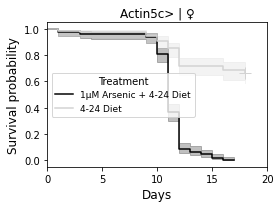

[KM SUMMARY] Genotype=Actin5c> | Sex=Female
  Median lifespan (days):
    1µM Arsenic + 4-24 Diet: 11.0
    4-24 Diet           : inf
  Time to 90% death (LT90, days):
    1µM Arsenic + 4-24 Diet: 12.0
    4-24 Diet           : nan
  Pairwise log-rank p-values (Treatments within panel):
    1µM Arsenic + 4-24 Diet  vs  4-24 Diet: p = <1e-4




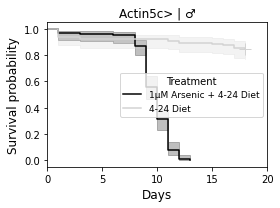

[KM SUMMARY] Genotype=Actin5c> | Sex=Male
  Median lifespan (days):
    1µM Arsenic + 4-24 Diet: 10.0
    4-24 Diet           : inf
  Time to 90% death (LT90, days):
    1µM Arsenic + 4-24 Diet: 11.0
    4-24 Diet           : nan
  Pairwise log-rank p-values (Treatments within panel):
    1µM Arsenic + 4-24 Diet  vs  4-24 Diet: p = <1e-4




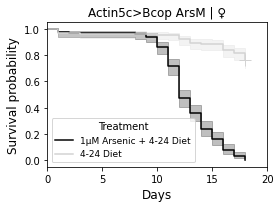

[KM SUMMARY] Genotype=Actin5c>Bcop ArsM | Sex=Female
  Median lifespan (days):
    1µM Arsenic + 4-24 Diet: 12.0
    4-24 Diet           : inf
  Time to 90% death (LT90, days):
    1µM Arsenic + 4-24 Diet: 16.0
    4-24 Diet           : nan
  Pairwise log-rank p-values (Treatments within panel):
    1µM Arsenic + 4-24 Diet  vs  4-24 Diet: p = <1e-4




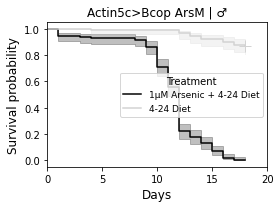

[KM SUMMARY] Genotype=Actin5c>Bcop ArsM | Sex=Male
  Median lifespan (days):
    1µM Arsenic + 4-24 Diet: 12.0
    4-24 Diet           : inf
  Time to 90% death (LT90, days):
    1µM Arsenic + 4-24 Diet: 15.0
    4-24 Diet           : nan
  Pairwise log-rank p-values (Treatments within panel):
    1µM Arsenic + 4-24 Diet  vs  4-24 Diet: p = <1e-4




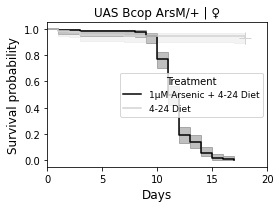

[KM SUMMARY] Genotype=UAS Bcop ArsM/+ | Sex=Female
  Median lifespan (days):
    1µM Arsenic + 4-24 Diet: 11.0
    4-24 Diet           : inf
  Time to 90% death (LT90, days):
    1µM Arsenic + 4-24 Diet: 14.0
    4-24 Diet           : nan
  Pairwise log-rank p-values (Treatments within panel):
    1µM Arsenic + 4-24 Diet  vs  4-24 Diet: p = <1e-4




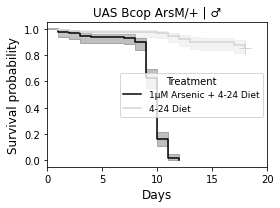

[KM SUMMARY] Genotype=UAS Bcop ArsM/+ | Sex=Male
  Median lifespan (days):
    1µM Arsenic + 4-24 Diet: 10.0
    4-24 Diet           : inf
  Time to 90% death (LT90, days):
    1µM Arsenic + 4-24 Diet: 11.0
    4-24 Diet           : nan
  Pairwise log-rank p-values (Treatments within panel):
    1µM Arsenic + 4-24 Diet  vs  4-24 Diet: p = <1e-4




In [33]:
# One plot per Genotype × Sex; within each plot, curves for all Treatments
cmap={'1µM Arsenic + 4-24 Diet':'#000000', '4-24 Diet':'#D3D3D3'}
for geno, df_g in long_df.groupby("Genotype", observed=True):
    for Sex, df_gs in df_g.groupby("Sex", observed=True):
        if df_gs.empty:
            continue

   
        kmf = KaplanMeierFitter()

        medians = {}
        lt90 = {}
        plt.figure(figsize=(4, 3))
        # fit and plot per Treatment
        for trt, df_gst in df_gs.groupby("Treatment", observed=True):
            if df_gst.empty:
                continue
            kmf.fit(
                durations=df_gst["duration"],
                event_observed=df_gst["event"],
                label=str(trt),
            )
            kmf.plot(ci_show=True, show_censors=True, color=cmap[trt])
            medians[trt] = kmf.median_survival_time_
            lt90[trt] = time_to_fraction_death_from_kmf(kmf, frac=0.9)

        # figure labeling

        plt.xlabel("Days")
        plt.ylabel("Survival probability")
        plt.xlabel("Days", fontsize=12)
        plt.ylabel("Survival probability", fontsize=12)
        plt.title(f"{geno} | {sex_map[Sex]}")
        plt.xlim(0,20)

        plt.legend(title="Treatment", fontsize=9, title_fontsize=10, loc="best")
        plt.tight_layout()
        g=geno.replace("/","")
        if 'Actin5c>Bcop' in g:
            plt.savefig(f"figures/survival_curves/KM_treatment_{g}_{Sex}.svg",format='svg')
        plt.show()

        # --- Pairwise log-rank tests across Treatments in this panel ---
        # Build data dict for quick access
        trt_groups = {}
        for trt, df_gst in df_gs.groupby("Treatment", observed=True):
            if not df_gst.empty:
                trt_groups[trt] = (
                    df_gst["duration"].to_numpy(),
                    df_gst["event"].to_numpy()
                )

        # all unique pairs
        trts = list(trt_groups.keys())
        pairs = []
        pvals = []
        for i in range(len(trts)):
            for j in range(i + 1, len(trts)):
                a, b = trts[i], trts[j]
                dur_a, evt_a = trt_groups[a]
                dur_b, evt_b = trt_groups[b]
                if len(dur_a) == 0 or len(dur_b) == 0:
                    p = np.nan
                else:
                    res = logrank_test(dur_a, dur_b, event_observed_A=evt_a, event_observed_B=evt_b, alpha=0.95)
                    p = float(res.p_value) if np.isfinite(res.p_value) else np.nan
                pairs.append((a, b))
                pvals.append(p)
        pvals = np.array(pvals, dtype=float)


        # --- print summary for this Genotype × Sex ---
        print(f"[KM SUMMARY] Genotype={geno} | Sex={Sex}")
        print("  Median lifespan (days):")
        for trt in trts:
            m = medians.get(trt, np.nan)
            print(f"    {str(trt):20s}: {np.nan if pd.isna(m) else round(float(m), 2)}")
        print("  Time to 90% death (LT90, days):")
        for trt in trts:
            l = lt90.get(trt, np.nan)
            print(f"    {str(trt):20s}: {np.nan if pd.isna(l) else round(float(l), 2)}")

        print("  Pairwise log-rank p-values (Treatments within panel):")
        if len(pairs) == 0:
            print("    (no comparable Treatment pairs)")
        else:
            for (a, b), p_raw in zip(pairs, pvals):
           
                p_raw_str = "<1e-4" if (isinstance(p_raw, float) and p_raw < 1e-4) else ( "NA" if (not np.isfinite(p_raw)) else f"{p_raw:.3g}" )
                print(f"    {a}  vs  {b}: p = {p_raw_str}")
        print("\n")
      

## Arsenic

In [34]:
dfm = long_df.copy()
dfm["Genotype"] = pd.Categorical(dfm["Genotype"], categories=['Actin5c>','UAS Bcop ArsM/+','Actin5c>Bcop ArsM'], ordered=False)
dfm["Treatment"] = pd.Categorical(dfm["Treatment"], categories=['4-24 Diet', '1µM Arsenic + 4-24 Diet'], ordered=False)
dfm["Sex"] = pd.Categorical(dfm["Sex"], categories=["Male","Female"], ordered=False)
# --- 2) Fit Cox PH 
cph = CoxPHFitter()
cph.fit(
    dfm,
    duration_col="duration",
    event_col="event",
    formula="Treatment + Genotype + Sex",
    cluster_col="Repeat",   
    robust=True
)

# View results (coefficients, HRs, p-values, CIs)
cph.summary

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
Treatment[T.1µM Arsenic + 4-24 Diet],3.534303,34.271132,0.371089,2.806983,4.261624,16.559883,70.925049,0.0,9.524150,1.663986e-21,69.025846
Genotype[T.UAS Bcop ArsM/+],-0.147511,0.862853,0.111881,-0.366795,0.071772,0.692952,1.074411,0.0,-1.318461,1.873493e-01,2.416198
Genotype[T.Actin5c>Bcop ArsM],-0.841586,0.431026,0.155243,-1.145856,-0.537316,0.317952,0.584315,0.0,-5.421101,5.923295e-08,24.009025
Sex[T.Female],-0.607087,0.544936,0.116562,-0.835543,-0.378630,0.433639,0.684799,0.0,-5.208292,1.905868e-07,22.323049


In [35]:
import pandas as pd
import numpy as np
from lifelines import CoxPHFitter

treatments = list(set(long_df.Treatment))
sexes = list(set(long_df.Sex))


bases = ["UAS Bcop ArsM/+", "Actin5c>"]

def run_cox_for_subset(df_subset: pd.DataFrame, base_genotype: str, other):
    """
    Fit Cox PH with Genotype as categorical and a chosen reference (base_genotype).
    Returns a list of dict rows (one per non-reference genotype level in the model).
    """
    
    df_subset["Genotype"] = pd.Categorical(df_subset["Genotype"], categories=[base_genotype, other], ordered=False)
    cph = CoxPHFitter()
    cph.fit(
        df_subset,
        duration_col="duration",
        event_col="event",
        formula='Genotype',
        cluster_col="Repeat",
        robust=True
    )

    r = cph.summary

    out_rows={"Comparison": f"{other} vs {base_genotype}", "HR": r["exp(coef)"].values[0], "HR 95% CI (lower)": r["exp(coef) lower 95%"].values[0], "HR 95% CI (upper)": r["exp(coef) upper 95%"].values[0], "p-value": r["p"].values[0]}

    return out_rows

results = []

for treatment in treatments:
    for sex in sexes:
        for base in bases:
            try:
                df_subset = long_df[ (long_df["Treatment"] == treatment) & (long_df["Sex"] == sex) & ~(long_df['Genotype'].isin(set(bases)-set([base])))].copy()
          
                row = run_cox_for_subset(df_subset, base, 'Actin5c>Bcop ArsM')
                row.update({"Treatment": treatment, "Sex": sex, "Base": base})
                results.append(row)
            except Exception as e:
                # If a model fails (e.g., complete separation / zero events), record a row noting failure
                results.append({
                    "Comparison": f"(model failed) vs base={base}",
                    "Treatment": treatment,
                    "Sex": sex,
                    "Base": base,
                    "HR": np.nan,
                    "HR 95% CI (lower)": np.nan,
                    "HR 95% CI (upper)": np.nan,
                    "p-value": np.nan,
                    "error": str(e),
                })

results_df = pd.DataFrame(results)


col_order = ["Comparison", "Treatment", "Sex", "Base", "HR", "HR 95% CI (lower)", "HR 95% CI (upper)", "p-value"]


results_df = results_df.loc[:, col_order]


In [36]:
results_df

,Comparison,Treatment,Sex,Base,HR,HR 95% CI (lower),HR 95% CI (upper),p-value
0,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,1µM Arsenic + 4-24 Diet,Male,UAS Bcop ArsM/+,0.198860,0.130863,0.302189,3.874333e-14
1,Actin5c>Bcop ArsM vs Actin5c>,1µM Arsenic + 4-24 Diet,Male,Actin5c>,0.288888,0.193623,0.431024,1.184108e-09
2,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,1µM Arsenic + 4-24 Diet,Female,UAS Bcop ArsM/+,0.492880,0.385034,0.630931,1.959629e-08
3,Actin5c>Bcop ArsM vs Actin5c>,1µM Arsenic + 4-24 Diet,Female,Actin5c>,0.399720,0.291242,0.548602,1.373910e-08
4,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,4-24 Diet,Male,UAS Bcop ArsM/+,0.894677,0.165083,4.848758,8.973025e-01
5,Actin5c>Bcop ArsM vs Actin5c>,4-24 Diet,Male,Actin5c>,0.825446,0.310265,2.196062,7.007964e-01
6,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,4-24 Diet,Female,UAS Bcop ArsM/+,3.770739,1.584528,8.973318,2.695203e-03
7,Actin5c>Bcop ArsM vs Actin5c>,4-24 Diet,Female,Actin5c>,0.622982,0.180870,2.145772,4.532663e-01


In [37]:
display_df = results_df.copy()

display_df["HR"] = display_df["HR"].map(lambda x: f"{x:.2f}")
display_df["HR 95% CI (lower)"] = display_df["HR 95% CI (lower)"].map(lambda x: f"{x:.2f}")
display_df["HR 95% CI (upper)"] = display_df["HR 95% CI (upper)"].map(lambda x: f"{x:.2f}")
display_df["p-value"] = display_df["p-value"].map(lambda x: f"{x:.2e}")
display_df.drop('Base',axis=1)

,Comparison,Treatment,Sex,HR,HR 95% CI (lower),HR 95% CI (upper),p-value
0,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,1µM Arsenic + 4-24 Diet,Male,0.20,0.13,0.30,3.87e-14
1,Actin5c>Bcop ArsM vs Actin5c>,1µM Arsenic + 4-24 Diet,Male,0.29,0.19,0.43,1.18e-09
2,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,1µM Arsenic + 4-24 Diet,Female,0.49,0.39,0.63,1.96e-08
3,Actin5c>Bcop ArsM vs Actin5c>,1µM Arsenic + 4-24 Diet,Female,0.40,0.29,0.55,1.37e-08
4,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,4-24 Diet,Male,0.89,0.17,4.85,8.97e-01
5,Actin5c>Bcop ArsM vs Actin5c>,4-24 Diet,Male,0.83,0.31,2.20,7.01e-01
6,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,4-24 Diet,Female,3.77,1.58,8.97,2.70e-03
7,Actin5c>Bcop ArsM vs Actin5c>,4-24 Diet,Female,0.62,0.18,2.15,4.53e-01


In [38]:
## rerun with filtered_df excluding non-monotonic rows

treatments = list(set(long_df_filtered.Treatment))
sexes = list(set(long_df_filtered.Sex))


bases = ["UAS Bcop ArsM/+", "Actin5c>"]

def run_cox_for_subset(df_subset: pd.DataFrame, base_genotype: str, other):
    """
    Fit Cox PH with Genotype as categorical and a chosen reference (base_genotype).
    Returns a list of dict rows (one per non-reference genotype level in the model).
    """
    
    df_subset["Genotype"] = pd.Categorical(df_subset["Genotype"], categories=[base_genotype, other], ordered=False)
    cph = CoxPHFitter()
    cph.fit(
        df_subset,
        duration_col="duration",
        event_col="event",
        formula='Genotype',
        cluster_col="Repeat",
        robust=True
    )

    r = cph.summary

    out_rows={"Comparison": f"{other} vs {base_genotype}", "HR": r["exp(coef)"].values[0], "HR 95% CI (lower)": r["exp(coef) lower 95%"].values[0], "HR 95% CI (upper)": r["exp(coef) upper 95%"].values[0], "p-value": r["p"].values[0]}

    return out_rows

results = []

for treatment in treatments:
    for sex in sexes:
        for base in bases:
            try:
                df_subset = long_df_filtered[ (long_df_filtered["Treatment"] == treatment) & (long_df_filtered["Sex"] == sex) & ~(long_df_filtered['Genotype'].isin(set(bases)-set([base])))].copy()
          
                row = run_cox_for_subset(df_subset, base, 'Actin5c>Bcop ArsM')
                row.update({"Treatment": treatment, "Sex": sex, "Base": base})
                results.append(row)
            except Exception as e:
                # If a model fails (e.g., complete separation / zero events), record a row noting failure
                results.append({
                    "Comparison": f"(model failed) vs base={base}",
                    "Treatment": treatment,
                    "Sex": sex,
                    "Base": base,
                    "HR": np.nan,
                    "HR 95% CI (lower)": np.nan,
                    "HR 95% CI (upper)": np.nan,
                    "p-value": np.nan,
                    "error": str(e),
                })

results_df = pd.DataFrame(results)


col_order = ["Comparison", "Treatment", "Sex", "Base", "HR", "HR 95% CI (lower)", "HR 95% CI (upper)", "p-value"]


results_df = results_df.loc[:, col_order]


In [39]:

results_df 

,Comparison,Treatment,Sex,Base,HR,HR 95% CI (lower),HR 95% CI (upper),p-value
0,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,1µM Arsenic + 4-24 Diet,Male,UAS Bcop ArsM/+,0.176834,0.118912,0.262971,1.157179e-17
1,Actin5c>Bcop ArsM vs Actin5c>,1µM Arsenic + 4-24 Diet,Male,Actin5c>,0.264850,0.180254,0.389147,1.312748e-11
2,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,1µM Arsenic + 4-24 Diet,Female,UAS Bcop ArsM/+,0.492880,0.385034,0.630931,1.959629e-08
3,Actin5c>Bcop ArsM vs Actin5c>,1µM Arsenic + 4-24 Diet,Female,Actin5c>,0.421645,0.319858,0.555823,8.996751e-10
4,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,4-24 Diet,Male,UAS Bcop ArsM/+,0.894677,0.165083,4.848758,8.973025e-01
5,Actin5c>Bcop ArsM vs Actin5c>,4-24 Diet,Male,Actin5c>,0.825446,0.310265,2.196062,7.007964e-01
6,Actin5c>Bcop ArsM vs UAS Bcop ArsM/+,4-24 Diet,Female,UAS Bcop ArsM/+,3.770739,1.584528,8.973318,2.695203e-03
7,Actin5c>Bcop ArsM vs Actin5c>,4-24 Diet,Female,Actin5c>,0.622982,0.180870,2.145772,4.532663e-01
